Libraries Imported Successfully!


Saving ott dataset 34.csv to ott dataset 34.csv

Dataset Loaded Successfully!
  show_id             title     type         country  date_added  \
0    S001  The Last Kingdom  TV Show   United States  2024-01-10   
1    S002        Ocean Deep    Movie           India  2023-11-05   
2    S003       City Lights    Movie  United Kingdom  2024-02-14   
3    S004          Code Red  TV Show   United States  2023-08-20   
4    S005       Spice Route    Movie           India  2022-06-12   

   release_year   rating   duration          listed_in  
0          2023    TV-MA  3 Seasons  Drama, Historical  
1          2022  U/A 13+    118 min      Documentaries  
2          2024  U/A 16+    105 min     Romance, Drama  
3          2021    TV-14  2 Seasons      Action, Crime  
4          2020  U/A 13+    132 min      Comedy, Drama  

Dataset Shape: (40, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 9 columns):
 #   Column        Non-

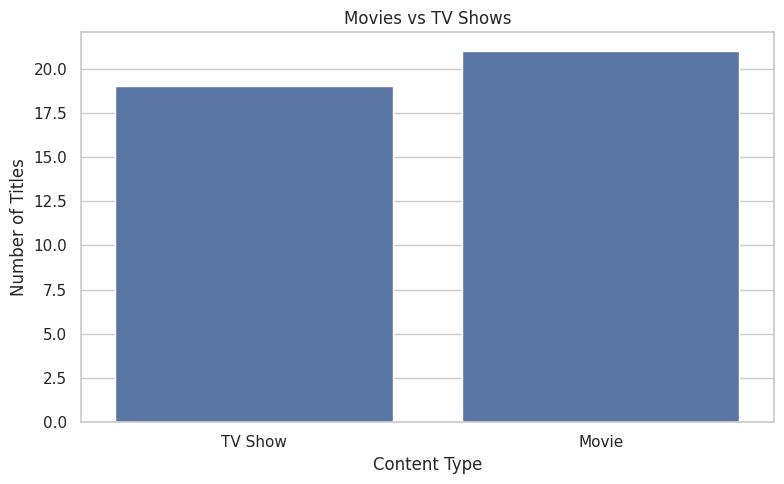

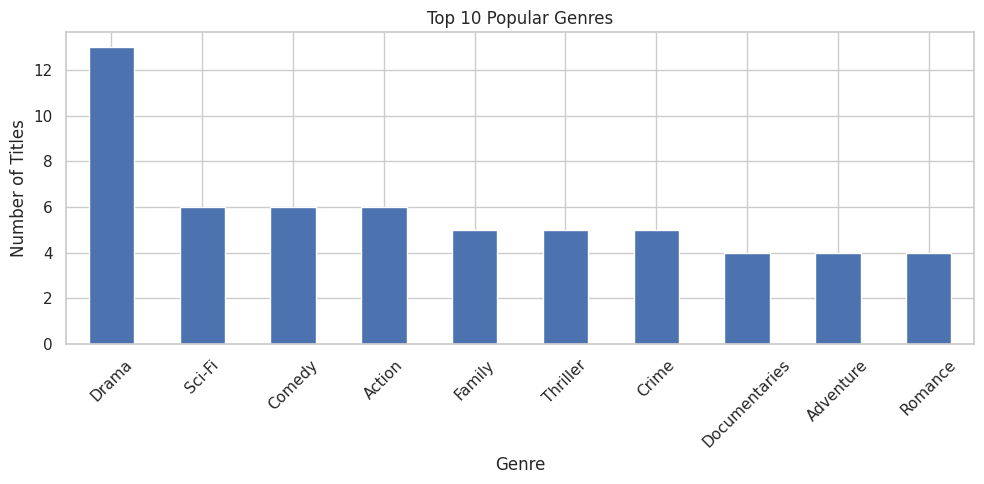

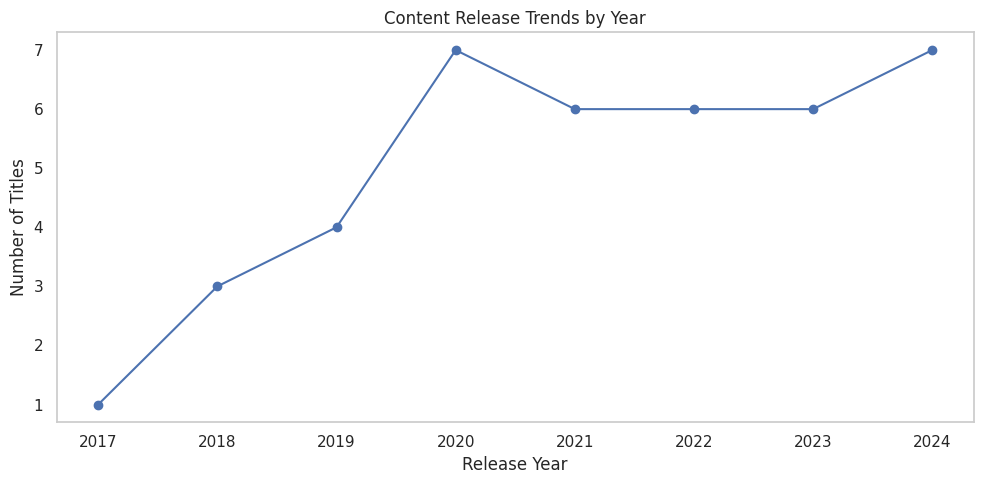

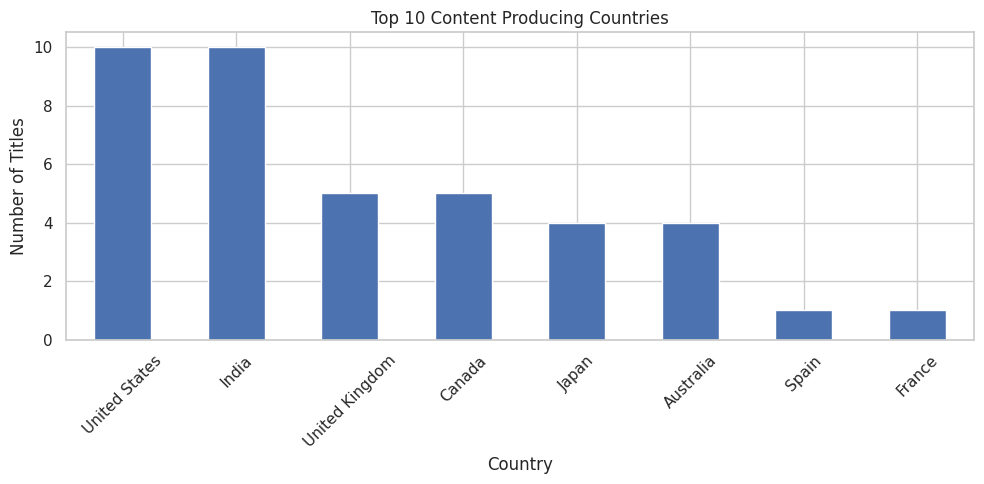

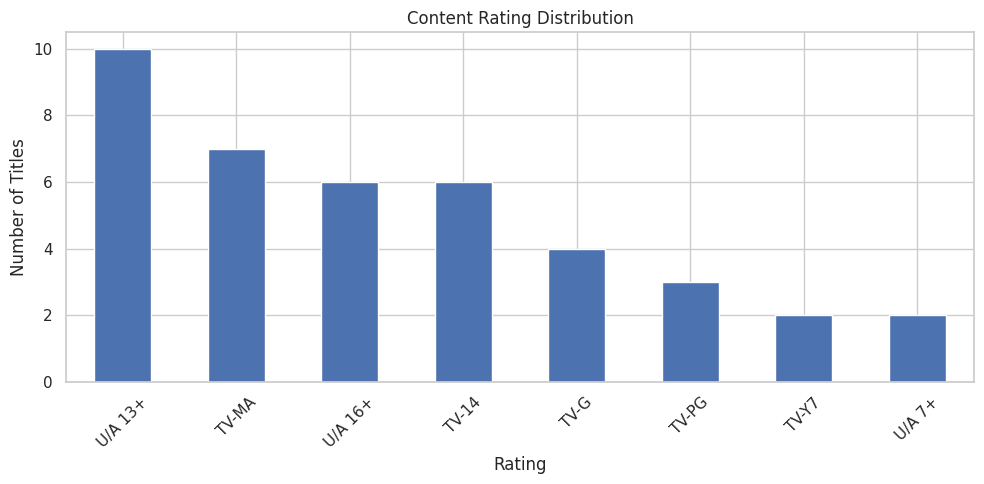

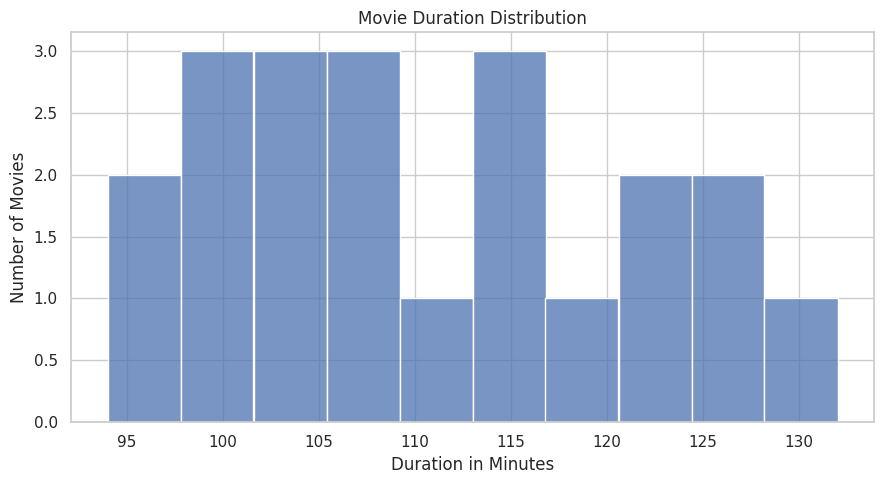


========== Total Titles ==========
   total_titles
0            40

========== Movies vs TV Shows ==========
      type  total
0    Movie     21
1  TV Show     19

========== Country Analysis ==========
          country  total
0   United States     10
1           India     10
2  United Kingdom      5
3          Canada      5
4           Japan      4
5       Australia      4
6           Spain      1
7          France      1

========== Genre Analysis ==========
                listed_in  total
0   Documentaries, Nature      3
1           Food, Reality      2
2         Crime, Thriller      2
3                Thriller      1
4           Sci-Fi, Drama      1
5       Sci-Fi, Adventure      1
6          Sci-Fi, Action      1
7                  Sci-Fi      1
8          Romance, Drama      1
9         Romance, Comedy      1
10        Reality, Travel      1
11         Music, Romance      1
12           Kids, Sci-Fi      1
13           Kids, Family      1
14          Family, Drama      1
15   

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:

# ==========================================
# OTT STREAMING CONTENT TREND ANALYSIS
# Complete Project - Python + SQL + EDA
# ==========================================

# STEP 1: INSTALL LIBRARIES
!pip install pandas matplotlib seaborn -q

# STEP 2: IMPORT LIBRARIES
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
from google.colab import files

sns.set_theme(style="whitegrid")

print("Libraries Imported Successfully!")

# STEP 3: UPLOAD DATASET
uploaded = files.upload()

file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)

print("\nDataset Loaded Successfully!")
print(df.head())

# STEP 4: DATASET INFORMATION
print("\nDataset Shape:", df.shape)
print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

# STEP 5: DATA CLEANING
df = df.drop_duplicates()

df = df.dropna(
    subset=['title', 'type', 'release_year']
)

df['date_added'] = pd.to_datetime(
    df['date_added'], errors='coerce'
)

df['release_year'] = pd.to_numeric(
    df['release_year'], errors='coerce'
)

df = df.dropna(subset=['release_year'])
df['release_year'] = df['release_year'].astype(int)

print("\nData Cleaning Completed!")
print("Clean Dataset Shape:", df.shape)

# STEP 6: BASIC ANALYSIS
print("\nTotal Titles:", len(df))
print("\nContent Types:")
print(df['type'].value_counts())

print("\nTop Countries:")
print(df['country'].value_counts().head(10))

print("\nContent Ratings:")
print(df['rating'].value_counts())

print("\nRelease Year Analysis:")
print(df['release_year'].value_counts().sort_index())

# STEP 7: GENRE ANALYSIS
genres = df['listed_in'].dropna().str.split(', ').explode()

print("\nTop 10 Genres:")
print(genres.value_counts().head(10))

# ==========================================
# STEP 8: VISUALIZATION 1
# MOVIES VS TV SHOWS
# ==========================================

plt.figure(figsize=(8,5))
sns.countplot(data=df, x='type')
plt.title('Movies vs TV Shows')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')
plt.tight_layout()
plt.show()

# ==========================================
# STEP 9: VISUALIZATION 2
# TOP 10 GENRES
# ==========================================

plt.figure(figsize=(10,5))
genres.value_counts().head(10).plot(kind='bar')
plt.title('Top 10 Popular Genres')
plt.xlabel('Genre')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ==========================================
# STEP 10: VISUALIZATION 3
# RELEASE YEAR TRENDS
# ==========================================

plt.figure(figsize=(10,5))
df['release_year'].value_counts().sort_index().plot(
    kind='line', marker='o'
)
plt.title('Content Release Trends by Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.grid()
plt.tight_layout()
plt.show()

# ==========================================
# STEP 11: VISUALIZATION 4
# TOP 10 COUNTRIES
# ==========================================

plt.figure(figsize=(10,5))
df['country'].dropna().value_counts().head(10).plot(
    kind='bar'
)
plt.title('Top 10 Content Producing Countries')
plt.xlabel('Country')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ==========================================
# STEP 12: VISUALIZATION 5
# CONTENT RATINGS
# ==========================================

plt.figure(figsize=(10,5))
df['rating'].value_counts().plot(kind='bar')
plt.title('Content Rating Distribution')
plt.xlabel('Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ==========================================
# STEP 13: VISUALIZATION 6
# MOVIE DURATION ANALYSIS
# ==========================================

movies = df[df['type'] == 'Movie'].copy()

movies['duration_minutes'] = pd.to_numeric(
    movies['duration'].astype(str).str.extract(r'(\d+)')[0],
    errors='coerce'
)

plt.figure(figsize=(9,5))
sns.histplot(
    movies['duration_minutes'].dropna(),
    bins=10
)
plt.title('Movie Duration Distribution')
plt.xlabel('Duration in Minutes')
plt.ylabel('Number of Movies')
plt.tight_layout()
plt.show()

# ==========================================
# STEP 14: SQL ANALYSIS
# ==========================================

conn = sqlite3.connect('ott_analysis.db')

df.to_sql(
    'ott_content',
    conn,
    if_exists='replace',
    index=False
)

queries = {
    "Total Titles":
    """SELECT COUNT(*) AS total_titles
       FROM ott_content""",

    "Movies vs TV Shows":
    """SELECT type, COUNT(*) AS total
       FROM ott_content
       GROUP BY type""",

    "Country Analysis":
    """SELECT country, COUNT(*) AS total
       FROM ott_content
       GROUP BY country
       ORDER BY total DESC""",

    "Genre Analysis":
    """SELECT listed_in, COUNT(*) AS total
       FROM ott_content
       GROUP BY listed_in
       ORDER BY total DESC""",

    "Rating Analysis":
    """SELECT rating, COUNT(*) AS total
       FROM ott_content
       GROUP BY rating
       ORDER BY total DESC""",

    "Year Wise Analysis":
    """SELECT release_year, COUNT(*) AS total
       FROM ott_content
       GROUP BY release_year
       ORDER BY release_year"""
}

for title, query in queries.items():
    print("\n==========", title, "==========")
    print(pd.read_sql_query(query, conn))

conn.close()

# ==========================================
# STEP 15: CONTENT STRATEGY INSIGHTS
# ==========================================

print("\n========== CONTENT STRATEGY MEMO ==========")

print("\n1. GENRE STRATEGY")
print("Identify the most frequent genres and consider")
print("prioritizing similar content acquisitions.")

print("\n2. REGIONAL STRATEGY")
print("Compare country-wise content distribution and")
print("explore opportunities for regional expansion.")

print("\n3. CONTENT FORMAT STRATEGY")
print("Compare Movies and TV Shows to understand")
print("the catalog's content format distribution.")

# ==========================================
# STEP 16: FINAL SUMMARY
# ==========================================

print("\n========== FINAL PROJECT SUMMARY ==========")

print("Total Titles:", len(df))
print("Total Movies:", (df['type'] == 'Movie').sum())
print("Total TV Shows:", (df['type'] == 'TV Show').sum())
print("Total Countries:", df['country'].nunique())
print("Total Genres:", genres.nunique())
print("Release Year Range:",
      df['release_year'].min(), "to",
      df['release_year'].max())

# SAVE CLEANED DATA
df.to_csv('OTT_Cleaned_Data.csv', index=False)

print("\nPROJECT COMPLETED SUCCESSFULLY!")
print("6 Visualizations Created!")
print("SQL Analysis Completed!")
print("Cleaned Dataset Saved!")

# DOWNLOAD CLEANED DATA
files.download('OTT_Cleaned_Data.csv')
